In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df=pd.read_csv('/content/creditcard.csv')

In [ ]:
print(df.shape)
df.head()

(39702, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


In [ ]:
print(df["Class"].value_counts())
print("Missing values in Class:", df["Class"].isna().sum())

df = df.dropna(subset=["Class"])

Class
0.0    39597
1.0      104
Name: count, dtype: int64
Missing values in Class: 0


In [ ]:
X=df.drop('Class', axis=1)
y=df['Class']

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
print("Training data : ", X_train.shape)
print("Testing data : ", X_test.shape)

Training data :  (31760, 30)
Testing data :  (7941, 30)


In [ ]:
from sklearn.ensemble import RandomForestClassifier
model=RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=42
)
model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=10, random_state=42)

In [ ]:
y_pred=model.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
print("Accuracy : ", accuracy_score(y_test, y_pred))
print("CLassification Report : ")
print(classification_report(y_test, y_pred))
print("Confusion matrix : ")
print(confusion_matrix(y_test, y_pred))

Accuracy :  0.9993703563782899
CLassification Report : 
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      7920
         1.0       0.94      0.81      0.87        21

    accuracy                           1.00      7941
   macro avg       0.97      0.90      0.94      7941
weighted avg       1.00      1.00      1.00      7941

Confusion matrix : 
[[7919    1]
 [   4   17]]


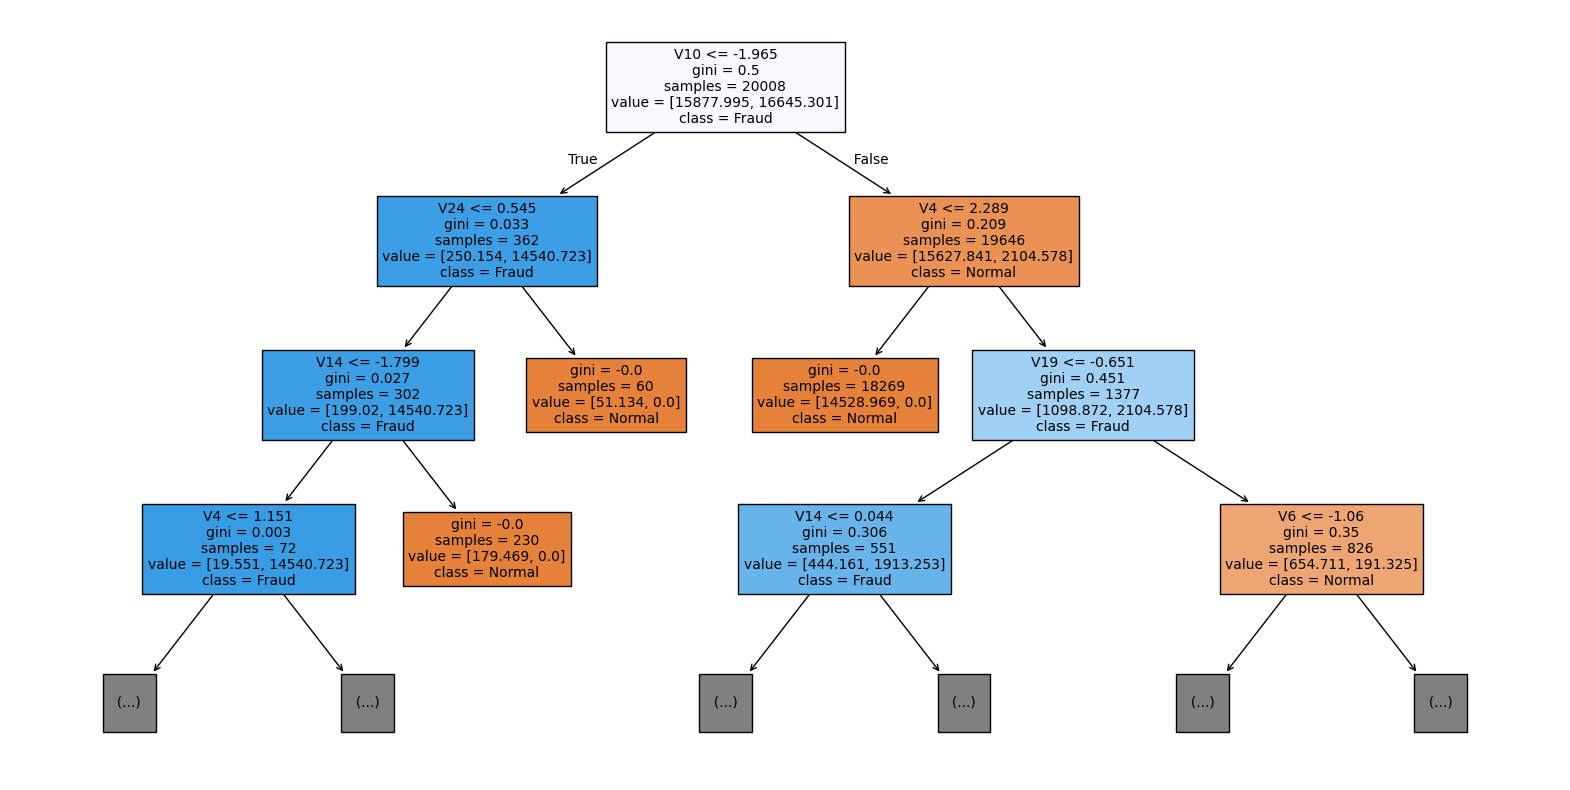

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    model.estimators_[50],
    max_depth=3,
    feature_names=X.columns,
    class_names=["Normal", "Fraud"],
    filled=True
)

plt.show()